# Adaptive-Threshold BEE

**Responsible member:** Areen  
**Method:** Adaptive-threshold BEE with Maskable PPO  
**Research question:** Can thresholds that respond to changing scarcity, contention and mission unmet demand improve ground-station schedule construction?

This notebook implements and verifies the adaptive BEE representation, selects its configuration using W40 only, freezes the selected rule, retrains it across five held-out-week folds and exports every model, schedule, metric, threshold trace, figure and report table required for final integration.


# 2. Environment Setup

## 2.1 Mount Google Drive


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 2.2 Install Required Packages


In [ ]:
!pip install -q pyarrow gymnasium stable-baselines3 sb3-contrib seaborn tensorboard rich tqdm

## 2.3 Define Directories


In [ ]:
from pathlib import Path
import sys

BEE_ROOT = Path("/content/drive/MyDrive/BEE")
PACKAGE_ROOT = BEE_ROOT / "shared_v2"
MEMBER_ROOT = BEE_ROOT / "member_4_adaptive"

DIRS = {
    "src": MEMBER_ROOT / "src",
    "models": MEMBER_ROOT / "adaptive_bee_models",
    "checkpoints": MEMBER_ROOT / "checkpoints",
    "results": MEMBER_ROOT / "results",
    "validation_runs": MEMBER_ROOT / "results" / "validation_runs",
    "cross_week_runs": MEMBER_ROOT / "results" / "cross_week_runs",
    "schedules": MEMBER_ROOT / "adaptive_bee_schedules",
    "thresholds": MEMBER_ROOT / "adaptive_threshold_traces",
    "figures": MEMBER_ROOT / "adaptive_bee_figures",
    "configs": MEMBER_ROOT / "configs",
    "logs": MEMBER_ROOT / "logs",
    "report": MEMBER_ROOT / "report",
}

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

assert PACKAGE_ROOT.exists(), f"shared_v2 not found: {PACKAGE_ROOT}"

for path in [PACKAGE_ROOT / "src", DIRS["src"]]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

print("Shared package:", PACKAGE_ROOT)
print("Member output folder:", MEMBER_ROOT)

Shared package: /content/drive/MyDrive/BEE/shared_v2
Member output folder: /content/drive/MyDrive/BEE/member_4_adaptive


## 2.4 Imports, Random Seeds and Runtime Information


In [ ]:
import hashlib
import importlib
import json
import math
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from stable_baselines3.common.callbacks import CheckpointCallback
from stable_baselines3.common.monitor import Monitor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cpu"

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("CPU cores:", __import__("os").cpu_count())

Python: 3.13.16
PyTorch: 2.11.0+cu130
Device: cpu
CPU cores: 12


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section 3: Load Shared Project Package

## 3.1 Load the Shared Configuration, Data and Utilities


In [ ]:
from experiment_config import (
    PACKAGE_VERSION,
    CANONICAL_SPLIT,
    ROBUSTNESS_FOLDS,
    TRAINING_SEEDS,
    EVALUATION_SEEDS,
    MAX_REQUESTS,
    MAX_STEPS,
    TOTAL_TIMESTEPS,
    CHECKPOINT_FREQUENCY,
    PPO_CONFIG,
    RESULT_COLUMNS,
    SUMMARY_METRICS,
)

from experiment_utils import (load_shared_data, select_weeks,)

from validator import validate_schedule
import placement
from environment import BEEGroundStationEnv

REQUIRED_SHARED_FILES = [
    PACKAGE_ROOT / "data" / "processed" / "requests.parquet",
    PACKAGE_ROOT / "data" / "processed" / "visibility_periods.parquet",
    PACKAGE_ROOT / "data" / "processed" / "maintenance.parquet",
    PACKAGE_ROOT / "src" / "placement.py",
    PACKAGE_ROOT / "src" / "environment.py",
    PACKAGE_ROOT / "src" / "validator.py",
    PACKAGE_ROOT / "src" / "experiment_config.py",
    PACKAGE_ROOT / "src" / "experiment_utils.py",
]

missing_shared_files = [str(path) for path in REQUIRED_SHARED_FILES if not path.exists()]

assert not missing_shared_files, (f"Missing shared files: {missing_shared_files}")

assert PACKAGE_VERSION == "shared_v2"

request_table, visibility_table, maintenance_table = (load_shared_data(PACKAGE_ROOT))

print("Package version:", PACKAGE_VERSION)
print("Requests:", request_table.shape)
print("Visibility periods:", visibility_table.shape)
print("Maintenance intervals:", maintenance_table.shape)
print("Placement module:", placement.__file__)
print("Base environment:", BEEGroundStationEnv.__module__)

Package version: shared_v2
Requests: (1452, 21)
Visibility periods: (14699, 17)
Maintenance intervals: (1798, 6)
Placement module: /content/drive/MyDrive/BEE/shared_v2/src/placement.py
Base environment: environment


## 3.2 Verify Package Version and Manifest


In [ ]:
MANIFEST_PATH = PACKAGE_ROOT / "metadata" / "package_manifest.json"

with open(MANIFEST_PATH, "r") as file:
    package_manifest = json.load(file)

assert package_manifest["package_version"] == "shared_v2"
assert request_table["track_id"].is_unique
assert request_table["track_id"].notna().all()
assert set(request_table["week_key"].unique()) == set(["W10_2018", "W20_2018", "W30_2018", "W40_2018", "W50_2018"])
assert len(request_table) == 1452
assert request_table.isna().sum().sum() == 0

data_audit = (request_table.groupby("week_key").agg(requests=("track_id", "size"), missions=("subject", "nunique"),).reset_index())

display(data_audit)
display(request_table.dtypes.rename("dtype").to_frame())
display(request_table.isna().sum().rename("missing_values").to_frame())
print("Maximum weekly requests:", data_audit["requests"].max())
print("Shared module hashes:", package_manifest["modules"])

,week_key,requests,missions
0,W10_2018,257,30
1,W20_2018,294,33
2,W30_2018,293,32
3,W40_2018,333,34
4,W50_2018,275,29


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,dtype
week_key,object
week,int64
year,int64
subject,object
user,object
track_id,object
duration_seconds,int64
minimum_duration_seconds,int64
setup_seconds,int64
teardown_seconds,int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_values
week_key,0
week,0
year,0
subject,0
user,0
track_id,0
duration_seconds,0
minimum_duration_seconds,0
setup_seconds,0
teardown_seconds,0


Maximum weekly requests: 333
Shared module hashes: {'environment.py': 'bb5cc62f3dd23fff749b8591a7ce2a994abd05b220f66e90fbcb5544d7aebda7', 'experiment_config.py': '9704cd0c1000ff58fa9afb9eceaf18f995c9f0090c24d3213c2722a0c810269f', 'experiment_utils.py': 'a92190c7a0d02c641b2967886821cfe716220ec8297cc4d3bb59d9e58c0b80c1', 'placement.py': '6579b898b1c7047ea0ce9b04a55cdaec3ecde9408b694aa326f48c1d4e9fc4fd', 'validator.py': 'b1dcbb306d180fd723b31f078ccb6f1b1817bf7f23d04e49ee181e8b53badcf3'}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 4. Verify Shared Data

## 4.1 Dataset Structure and Integrity

The preceding audit displays the available scheduling weeks, request count per week, number of missions, maximum weekly request count, column data types, missing-value counts and unique request-identifier checks. These checks confirm that the shared processed tables are suitable for the adaptive-BEE experiments.


In [ ]:
week_verification = (request_table.groupby("week_key").agg(
        requests=("track_id", "size"),
        missions=("subject", "nunique"),
        unique_track_ids=("track_id", "nunique"),
    )
    .reset_index()
)

assert (week_verification["requests"] == week_verification["unique_track_ids"]).all()

display(week_verification)
print("Total missing values:", int(request_table.isna().sum().sum()))
print("Unique request identifiers:", request_table["track_id"].nunique())
print("Maximum request count:", int(week_verification["requests"].max()))

,week_key,requests,missions,unique_track_ids
0,W10_2018,257,30,257
1,W20_2018,294,33,294
2,W30_2018,293,32,293
3,W40_2018,333,34,333
4,W50_2018,275,29,275


Total missing values: 0
Unique request identifiers: 1452
Maximum request count: 333


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 5. Method Implementation

## 5.1 Adaptive BEE Method

The model retains the nine request-level scheduling features used by plain PPO and adds placement scarcity, resource contention, mission unmet demand, stimulus, threshold and activation. Stimulus is calculated as:

**Stimulus = w₁ × placement scarcity + w₂ × resource contention + w₃ × mission unmet demand**

Activation is calculated as:

**Activation = stimulus² ÷ (stimulus² + threshold²)**

The adaptive threshold begins at 0.50 and decreases according to the enabled pressure components. It is clipped to [0.10, 0.90]. The selective rule A6 applies adaptation only when at least two indicators exceed the limits fixed before validation: scarcity ≥ 0.30, contention increase ≥ 0.10 and relative unmet pressure ≥ 0.10.


## 5.2 Create the Fixed-BEE Feature Superclass


In [ ]:
%%writefile /content/drive/MyDrive/BEE/member_4_adaptive/src/bee_fixed_environment.py

import numpy as np
from gymnasium import spaces
from environment import BEEGroundStationEnv


class BEEFixedThresholdEnv(BEEGroundStationEnv):
    def __init__(
        self,
        requests,
        visibility_periods,
        maintenance,
        seed=42,
        max_requests=333,
        max_steps=1000,
        shuffle_requests=True,
        stimulus_weights=(0.4, 0.4, 0.2),
        fixed_threshold=0.5,
        sensitivity=2.0
    ):
        self.stimulus_weights = tuple(stimulus_weights)

        self.fixed_threshold = float(fixed_threshold)

        self.sensitivity = float(sensitivity)

        self.initial_candidate_counts = {}
        self.bee_feature_cache = {}

        super().__init__(
            requests=requests,
            visibility_periods=visibility_periods,
            maintenance=maintenance,
            include_bee_features=False,
            seed=seed,
            max_requests=max_requests,
            max_steps=max_steps,
            shuffle_requests=shuffle_requests
        )

        # Nine original request features plus six bee-inspired features
        self.request_feature_count = 15
        self.global_feature_count = 4

        observation_size = (self.max_requests * self.request_feature_count + self.global_feature_count)

        self.observation_space = spaces.Box(
            low=0.0,
            high=1.0,
            shape=(observation_size,),
            dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        self.initial_candidate_counts = {}
        self.bee_feature_cache = {}

        return super().reset(seed=seed, options=options,)

    def _refresh_candidates_and_mask(self, affected_antennas=None,):
        super()._refresh_candidates_and_mask(affected_antennas=affected_antennas)

        for action in range(len(self.requests)):
            current_count = len(self._candidate_cache.get(action, []))

            if action not in self.initial_candidate_counts:
                self.initial_candidate_counts[action] = (current_count)

        self._calculate_bee_features()

    def _candidate_antennas(self, action):
        antennas = set()

        for candidate in self._candidate_cache.get(action, [],):
            antennas.update(candidate["physical_antennas"])

        return antennas

    def _calculate_contention_scores(self):
        valid_actions = np.flatnonzero(self._action_mask[: len(self.requests)])

        action_antennas = {
            int(action): self._candidate_antennas(int(action))
            for action in valid_actions
        }

        antenna_to_actions = {}

        for action, antennas in action_antennas.items():
            for antenna in antennas:
                antenna_to_actions.setdefault(antenna, set())

                antenna_to_actions[antenna].add(action)

        denominator = max(len(valid_actions) - 1, 1)

        contention = {}

        for action, antennas in action_antennas.items():
            competitors = set()

            for antenna in antennas:
                competitors.update(antenna_to_actions.get(antenna, set()))

            competitors.discard(action)

            contention[action] = min(len(competitors) / denominator, 1.0)

        return contention

    def _calculate_bee_features(self):
        contention_scores = (self._calculate_contention_scores())

        self.bee_feature_cache = {}

        w_scarcity, w_contention, w_unmet = (self.stimulus_weights)

        for action in range(len(self.requests)):
            current_count = len(self._candidate_cache.get(action, []))

            initial_count = max(self.initial_candidate_counts.get(action, current_count,), 1)

            placement_scarcity = np.clip(1.0 - current_count / initial_count, 0.0, 1.0)

            resource_contention = float(contention_scores.get(action, 0.0))

            dynamic = (self._request_dynamic_features(action))

            mission_unmet_ratio = np.clip(dynamic["mission_unmet_ratio"], 0.0, 1.0)

            stimulus = np.clip(
                w_scarcity * placement_scarcity
                + w_contention
                * resource_contention
                + w_unmet
                * mission_unmet_ratio,
                0.0,
                1.0
            )

            numerator = (stimulus ** self.sensitivity)

            denominator = (numerator + self.fixed_threshold ** self.sensitivity + 1e-8)

            activation = np.clip(numerator / denominator, 0.0, 1.0)

            self.bee_feature_cache[action] = {
                "placement_scarcity": float(placement_scarcity),
                "resource_contention": float(resource_contention),
                "mission_unmet_ratio": float(mission_unmet_ratio),
                "stimulus": float(stimulus),
                "threshold": float(self.fixed_threshold),
                "activation": float(activation)
            }

    def get_bee_information(self, action):
        if action < 0 or action >= len(self.requests):
            raise IndexError(f"Action {action} is out of range.")

        return self.bee_feature_cache[int(action)].copy()

    def get_request_information(self, action):
        information = (super().get_request_information(action))

        information.update(self.get_bee_information(action))

        return information

    def _get_observation(self):
        constants = self._normalization_constants()

        request_features = np.zeros((self.max_requests, self.request_feature_count,), dtype=np.float32)

        for action in range(len(self.requests)):
            request = self.requests.iloc[action]

            dynamic = (self._request_dynamic_features(action))

            bee = self.bee_feature_cache.get(
                action,
                {
                    "placement_scarcity": 0.0,
                    "resource_contention": 0.0,
                    "mission_unmet_ratio": 0.0,
                    "stimulus": 0.0,
                    "threshold": self.fixed_threshold,
                    "activation": 0.0
                }
            )

            current_placements = dynamic["remaining_feasible_placements"]

            original_vps = max(int(request[ "number_of_visibility_periods"]),1)

            placement_ratio = np.clip(current_placements / original_vps, 0.0, 1.0)

            earliest_end_normalized = np.clip((dynamic["earliest_feasible_end"] - constants["week_start"])/ constants["week_span"], 0.0, 1.0)

            features = [
                float(action in self.scheduled_actions),
                float(self._action_mask[action]),
                min(float(request["duration_seconds"]) / constants["maximum_duration"], 1.0),
                min(float(request["minimum_duration_seconds"]) / constants["maximum_duration"], 1.0),
                min(float(request["setup_seconds"]) / constants["maximum_setup"], 1.0),
                min(float(request["teardown_seconds"]) / constants["maximum_teardown"], 1.0),
                min(float(request["number_of_resource_options"]) / constants["maximum_resources"], 1.0),
                float(placement_ratio),
                float(earliest_end_normalized),
                bee["placement_scarcity"],
                bee["resource_contention"],
                bee["mission_unmet_ratio"],
                bee["stimulus"],
                bee["threshold"],
                bee["activation"],
            ]

            request_features[action] = np.asarray(features, dtype=np.float32)

        allocated_seconds = sum(placement["allocated_seconds"] for placement in self.schedule)

        global_features = np.asarray(
            [
                len(self.scheduled_actions) / max(len(self.requests), 1),
                allocated_seconds / max(self.total_requested_seconds, 1.0),
                self._action_mask[ : len(self.requests)].sum() / max(len(self.requests), 1),
                min(self.step_count / max(self.max_steps, 1), 1.0),
            ],
            dtype=np.float32,
        )

        observation = np.concatenate([request_features.reshape(-1), global_features]).astype(np.float32)

        return np.clip(observation, 0.0, 1.0)

Overwriting /content/drive/MyDrive/BEE/member_4_adaptive/src/bee_fixed_environment.py


## 5.3 Create the Adaptive-BEE Environment


In [ ]:
%%writefile /content/drive/MyDrive/BEE/member_4_adaptive/src/bee_adaptive_environment.py

import numpy as np

from bee_fixed_environment import (BEEFixedThresholdEnv)


class BEEAdaptiveThresholdEnv(BEEFixedThresholdEnv):
    def __init__(
        self,
        requests,
        visibility_periods,
        maintenance,
        seed=42,
        max_requests=333,
        max_steps=1000,
        shuffle_requests=True,
        stimulus_weights=(0.4, 0.4, 0.2),
        base_threshold=0.5,
        sensitivity=2.0,
        scarcity_strength=0.20,
        contention_strength=0.15,
        unmet_strength=0.15,
        minimum_threshold=0.10,
        maximum_threshold=0.90,
        selective_mode=False,
        scarcity_indicator_limit=0.30,
        contention_indicator_limit=0.10,
        unmet_indicator_limit=0.10,
        minimum_pressure_indicators=2
    ):
        self.base_threshold = float(base_threshold)

        self.scarcity_strength = float(scarcity_strength)

        self.contention_strength = float(contention_strength)

        self.unmet_strength = float(unmet_strength)

        self.minimum_threshold = float(minimum_threshold)

        self.maximum_threshold = float(maximum_threshold)

        self.selective_mode = bool(selective_mode)

        self.scarcity_indicator_limit = float(scarcity_indicator_limit)

        self.contention_indicator_limit = float(contention_indicator_limit)

        self.unmet_indicator_limit = float(unmet_indicator_limit)

        self.minimum_pressure_indicators = int(minimum_pressure_indicators)

        self.initial_contention_scores = {}
        self.selected_bee_history = []

        super().__init__(
            requests=requests,
            visibility_periods=visibility_periods,
            maintenance=maintenance,
            seed=seed,
            max_requests=max_requests,
            max_steps=max_steps,
            shuffle_requests=shuffle_requests,
            stimulus_weights=stimulus_weights,
            fixed_threshold=base_threshold,
            sensitivity=sensitivity
        )

    def reset(self, seed=None, options=None):
        self.initial_contention_scores = {}
        self.selected_bee_history = []

        return super().reset(seed=seed, options=options)

    def _mean_mission_unmet_ratio(self):
        mission_ratios = []

        for subject, requested in (self.subject_requested_seconds.items()):
            allocated = (self.subject_allocated_seconds[str(subject)])

            if requested > 0:
                mission_ratios.append(1.0 - allocated / requested)

        if not mission_ratios:
            return 0.0

        return float(np.mean(mission_ratios))

    def _calculate_bee_features(self):
        # First calculate the same stimulus and fixed activation values used by the parent class
        super()._calculate_bee_features()

        mean_mission_unmet = (self._mean_mission_unmet_ratio())

        for action in range(len(self.requests)):
            bee = self.bee_feature_cache[action]

            current_contention = bee["resource_contention"]

            if (action not in self.initial_contention_scores):
                self.initial_contention_scores[action] = current_contention

            initial_contention = (self.initial_contention_scores[action])

            contention_increase = max(current_contention - initial_contention, 0.0)

            relative_unmet_pressure = max(bee["mission_unmet_ratio"] - mean_mission_unmet, 0.0)

            pressure_count = sum(
                [
                    bee["placement_scarcity"] >= self.scarcity_indicator_limit,
                    contention_increase >= self.contention_indicator_limit,
                    relative_unmet_pressure >= self.unmet_indicator_limit
                ]
            )

            adaptation_enabled = (not self.selective_mode or pressure_count >= self.minimum_pressure_indicators)

            if adaptation_enabled:
                adaptive_threshold = np.clip(
                    self.base_threshold - self.scarcity_strength * bee["placement_scarcity"] - self.contention_strength * contention_increase - self.unmet_strength * relative_unmet_pressure,
                    self.minimum_threshold,
                    self.maximum_threshold,
                )
            else:
                adaptive_threshold = (self.base_threshold)

            stimulus = bee["stimulus"]

            numerator = (stimulus ** self.sensitivity)

            denominator = (numerator + adaptive_threshold ** self.sensitivity + 1e-8)

            activation = np.clip(numerator / denominator, 0.0, 1.0)

            bee.update(
                {
                    "base_threshold": self.base_threshold,
                    "initial_contention": initial_contention,
                    "contention_increase": contention_increase,
                    "mean_mission_unmet": mean_mission_unmet,
                    "relative_unmet_pressure": relative_unmet_pressure,
                    "pressure_count": int(pressure_count),
                    "adaptation_enabled": bool(adaptation_enabled),
                    "threshold": float(adaptive_threshold),
                    "activation": float(activation)
                }
            )

    def step(self, action):
        action = int(action)

        selected_bee = None

        if (0 <= action < len(self.requests) and bool(self._action_mask[action])):
            selected_bee = self.get_bee_information(action)

            selected_bee.update(
                {
                    "step": int(self.step_count),
                    "action": action,
                    "track_id": str(self.requests.iloc[action]["track_id"])
                }
            )

        result = super().step(action)

        if selected_bee is not None:
            self.selected_bee_history.append(selected_bee)

        return result

    def get_selected_bee_summary(self):
        if not self.selected_bee_history:
            return {
                "mean_selected_stimulus": 0.0,
                "mean_selected_threshold": 0.0,
                "minimum_selected_threshold": 0.0,
                "maximum_selected_threshold": 0.0,
                "mean_selected_activation": 0.0
            }

        stimuli = np.asarray([row["stimulus"] for row in self.selected_bee_history], dtype=float)

        thresholds = np.asarray([row["threshold"] for row in self.selected_bee_history], dtype=float)

        activations = np.asarray([row["activation"] for row in self.selected_bee_history], dtype=float)

        return {
            "mean_selected_stimulus": float(stimuli.mean()),
            "mean_selected_threshold": float(thresholds.mean()),
            "minimum_selected_threshold": float(thresholds.min()),
            "maximum_selected_threshold": float(thresholds.max()),
            "mean_selected_activation": float(activations.mean())
        }

Overwriting /content/drive/MyDrive/BEE/member_4_adaptive/src/bee_adaptive_environment.py


## 5.4 Import the Model-Specific Environments


In [ ]:
for module_name in ["bee_fixed_environment", "bee_adaptive_environment"]:
    if module_name in sys.modules:
        del sys.modules[module_name]

importlib.invalidate_caches()

from bee_adaptive_environment import BEEAdaptiveThresholdEnv

print("Adaptive environment imported successfully.")

Adaptive environment imported successfully.


## 5.5 Define the Six Adaptive Configurations Before Validation


In [ ]:
COMMON_ADAPTIVE_PARAMETERS = {
    "stimulus_weights": [0.40, 0.40, 0.20],
    "base_threshold": 0.50,
    "sensitivity": 2.0,
    "minimum_threshold": 0.10,
    "maximum_threshold": 0.90,
    "scarcity_indicator_limit": 0.30,
    "contention_indicator_limit": 0.10,
    "unmet_indicator_limit": 0.10,
    "minimum_pressure_indicators": 2,
}

ADAPTIVE_CONFIGURATIONS = {
    "A1": {"scarcity_strength": 0.20, "contention_strength": 0.15, "unmet_strength": 0.15, "selective_mode": False},
    "A2": {"scarcity_strength": 0.20, "contention_strength": 0.00, "unmet_strength": 0.00, "selective_mode": False},
    "A3": {"scarcity_strength": 0.00, "contention_strength": 0.20, "unmet_strength": 0.00, "selective_mode": False},
    "A4": {"scarcity_strength": 0.00, "contention_strength": 0.00, "unmet_strength": 0.20, "selective_mode": False},
    "A5": {"scarcity_strength": 0.10, "contention_strength": 0.10, "unmet_strength": 0.10, "selective_mode": False},
    "A6": {"scarcity_strength": 0.20, "contention_strength": 0.15, "unmet_strength": 0.15, "selective_mode": True},
}

for configuration in ADAPTIVE_CONFIGURATIONS.values():
    configuration.update(COMMON_ADAPTIVE_PARAMETERS)

assert np.isclose(sum(COMMON_ADAPTIVE_PARAMETERS["stimulus_weights"]), 1.0)

display(pd.DataFrame(ADAPTIVE_CONFIGURATIONS).T)

,scarcity_strength,contention_strength,unmet_strength,selective_mode,stimulus_weights,base_threshold,sensitivity,minimum_threshold,maximum_threshold,scarcity_indicator_limit,contention_indicator_limit,unmet_indicator_limit,minimum_pressure_indicators
A1,0.2,0.15,0.15,False,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2
A2,0.2,0.0,0.0,False,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2
A3,0.0,0.2,0.0,False,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2
A4,0.0,0.0,0.2,False,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2
A5,0.1,0.1,0.1,False,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2
A6,0.2,0.15,0.15,True,"[0.4, 0.4, 0.2]",0.5,2.0,0.1,0.9,0.3,0.1,0.1,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5.6 Create Environment Factories


In [ ]:
def create_adaptive_environment(week_keys, seed, adaptive_configuration, shuffle_requests=True):
    requests, visibility, maintenance = select_weeks(request_table, visibility_table, maintenance_table, week_keys)

    return BEEAdaptiveThresholdEnv(
        requests=requests,
        visibility_periods=visibility,
        maintenance=maintenance,
        seed=seed,
        max_requests=MAX_REQUESTS,
        max_steps=MAX_STEPS,
        shuffle_requests=shuffle_requests,
        **adaptive_configuration,
    )


def action_mask_function(environment):
    return environment.action_masks()


def create_training_environment(week_keys, seed, adaptive_configuration):
    base_environment = create_adaptive_environment(
        week_keys=week_keys,
        seed=seed,
        adaptive_configuration=adaptive_configuration,
        shuffle_requests=True
    )

    masked_environment = ActionMasker(base_environment, action_mask_function)

    return Monitor(masked_environment)

# 6. Unit and Logic Tests

## 6.1 Observation, Range, Equation and Mask Tests


In [ ]:
test_configuration = ADAPTIVE_CONFIGURATIONS["A1"]

test_environment = create_adaptive_environment(
    week_keys=["W10_2018"],
    seed=SEED,
    adaptive_configuration=test_configuration,
    shuffle_requests=False
)

observation, reset_info = test_environment.reset(seed=SEED, options={"week_key": "W10_2018"})

assert observation.shape == (MAX_REQUESTS * 15 + 4,)
assert np.all((observation >= 0) & (observation <= 1))
assert np.allclose([row["threshold"] for row in test_environment.bee_feature_cache.values()], test_configuration["base_threshold"])

physical_mask_before = test_environment.action_masks().copy()
valid_action = int(np.flatnonzero(physical_mask_before)[0])
bee = test_environment.get_bee_information(valid_action)

manual_stimulus = np.clip(0.40 * bee["placement_scarcity"] + 0.40 * bee["resource_contention"] + 0.20 * bee["mission_unmet_ratio"], 0.0, 1.0)

manual_threshold = np.clip(0.50 - 0.20 * bee["placement_scarcity"] - 0.15 * bee["contention_increase"] - 0.15 * bee["relative_unmet_pressure"], 0.10, 0.90)

manual_activation = manual_stimulus ** 2 / (manual_stimulus ** 2 + manual_threshold ** 2 + 1e-8)

assert np.isclose(bee["stimulus"], manual_stimulus)
assert np.isclose(bee["threshold"], manual_threshold)
assert np.isclose(bee["activation"], manual_activation)
assert 0.10 <= bee["threshold"] <= 0.90
assert 0.0 <= bee["activation"] <= 1.0
assert np.array_equal(physical_mask_before, test_environment.action_masks())

print("Shape, range, equation and mask-independence tests passed.")

Shape, range, equation and mask-independence tests passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6.2 Threshold Change, Reset and Reproducibility Tests


In [ ]:
initial_thresholds = {action: row["threshold"] for action, row in test_environment.bee_feature_cache.items()}

for _ in range(10):
    valid_actions = np.flatnonzero(test_environment.action_masks())
    if len(valid_actions) == 0:
        break
    test_environment.step(int(valid_actions[0]))

current_thresholds = {action: row["threshold"] for action, row in test_environment.bee_feature_cache.items()}

assert any(
    not np.isclose(initial_thresholds[action], current_thresholds[action])
    for action in current_thresholds
    if action in initial_thresholds
)

test_environment.reset(seed=SEED, options={"week_key": "W10_2018"})

assert len(test_environment.schedule) == 0
assert len(test_environment.selected_bee_history) == 0
assert np.allclose([row["threshold"] for row in test_environment.bee_feature_cache.values()], 0.50)

env_a = create_adaptive_environment(["W10_2018"], 42, test_configuration, True)
env_b = create_adaptive_environment(["W10_2018"], 42, test_configuration, True)
obs_a, _ = env_a.reset(seed=42, options={"week_key": "W10_2018"})
obs_b, _ = env_b.reset(seed=42, options={"week_key": "W10_2018"})

assert np.array_equal(obs_a, obs_b)
assert np.array_equal(env_a.action_masks(), env_b.action_masks())

print("Threshold-change, reset and reproducibility tests passed.")

Threshold-change, reset and reproducibility tests passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6.3 Complete-Episode Constraint Test


In [ ]:
constraint_test_env = create_adaptive_environment(["W10_2018"], 42, test_configuration, True)
observation, _ = constraint_test_env.reset(seed=42, options={"week_key": "W10_2018"})

terminated = truncated = False

while not terminated and not truncated:
    valid_actions = np.flatnonzero(constraint_test_env.action_masks())
    if len(valid_actions) == 0:
        break
    observation, reward, terminated, truncated, info = constraint_test_env.step(int(valid_actions[0]))

constraint_test_report = validate_schedule(
    schedule=pd.DataFrame(constraint_test_env.schedule),
    requests=constraint_test_env.requests,
    visibility_periods=constraint_test_env.visibility,
    maintenance=constraint_test_env.maintenance,
)

assert constraint_test_report["constraint_violations"] == 0
print(constraint_test_report)

{'duplicate_request_violations': 0, 'duration_violations': 0, 'visibility_violations': 0, 'maintenance_violations': 0, 'antenna_overlap_violations': 0, 'resource_violations': 0, 'constraint_violations': 0}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 7. Configuration Selection

The six adaptive rules are selected using W10, W20 and W30 for training and W40 for validation. W50 is not loaded during model selection. The staged procedure reduces computational cost while retaining three-seed confirmation for the two finalists.

## 7.1 Resumable Training Utilities


In [ ]:
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def to_builtin(value):
    if isinstance(value, dict):
        return {str(key): to_builtin(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


def train_adaptive_model(run_type, run_id, training_weeks, training_seed, configuration_id, adaptive_configuration, target_timesteps):
    run_directory = (DIRS["models"] / run_type / run_id / f"seed_{training_seed}")
    run_directory.mkdir(parents=True, exist_ok=True)

    model_path = run_directory / "adaptive_bee_latest.zip"
    metadata_path = run_directory / "training_metadata.json"
    checkpoint_directory = run_directory / "checkpoints"
    checkpoint_directory.mkdir(parents=True, exist_ok=True)

    training_environment = create_training_environment(training_weeks, training_seed, adaptive_configuration)

    existing_metadata = None

    if metadata_path.exists():
        with open(metadata_path, "r") as file:
            existing_metadata = json.load(file)

    if model_path.exists():
        model = MaskablePPO.load(model_path, env=training_environment, device=DEVICE)
    else:
        model = MaskablePPO(
            "MlpPolicy",
            training_environment,
            seed=training_seed,
            device=DEVICE,
            verbose=0,
            tensorboard_log=str(DIRS["logs"] / run_type / run_id),
            **PPO_CONFIG
        )

    starting_timesteps = int(model.num_timesteps)
    remaining_timesteps = max(target_timesteps - starting_timesteps, 0)
    start_time = time.perf_counter()

    if remaining_timesteps > 0:
        callback = CheckpointCallback(
            save_freq=CHECKPOINT_FREQUENCY,
            save_path=str(checkpoint_directory),
            name_prefix="adaptive_bee",
            save_replay_buffer=False,
            save_vecnormalize=False
        )

        model.learn(
            total_timesteps=remaining_timesteps,
            reset_num_timesteps=False,
            callback=callback,
            progress_bar=True
        )

        model.save(model_path)

    runtime = time.perf_counter() - start_time

    if remaining_timesteps == 0 and existing_metadata is not None:
        training_environment.close()
        return model_path, existing_metadata

    final_episode_reward = None
    if model.ep_info_buffer:
        final_episode_reward = float(model.ep_info_buffer[-1]["r"])

    metadata = {
        "method": "adaptive_bee",
        "package_version": PACKAGE_VERSION,
        "run_type": run_type,
        "run_id": run_id,
        "configuration_id": configuration_id,
        "training_seed": training_seed,
        "training_weeks": list(training_weeks),
        "target_timesteps": target_timesteps,
        "starting_timesteps": starting_timesteps,
        "actual_timesteps": int(model.num_timesteps),
        "training_runtime_seconds": runtime,
        "final_episode_reward": final_episode_reward,
        "model_path": str(model_path),
        "model_hash": file_sha256(model_path)
    }

    with open(metadata_path, "w") as file:
        json.dump(to_builtin(metadata), file, indent=2)

    training_environment.close()
    return model_path, metadata

## 7.2 Resumable Validation Utility


In [ ]:
def evaluate_adaptive_model(
    model_path,
    run_type,
    run_id,
    configuration_id,
    adaptive_configuration,
    evaluation_week,
    training_weeks,
    training_seed,
    evaluation_seed,
    fold=None
):
    experiment_id = (f"{run_id}_train_{training_seed}_eval_{evaluation_seed}")

    result_root = (DIRS["validation_runs"] if run_type == "configuration_search" else DIRS["cross_week_runs"])

    result_path = result_root / f"{experiment_id}.json"
    schedule_path = DIRS["schedules"] / f"{experiment_id}.parquet"
    threshold_path = DIRS["thresholds"] / f"{experiment_id}.parquet"

    if result_path.exists() and schedule_path.exists() and threshold_path.exists():
        with open(result_path, "r") as file:
            return json.load(file)

    environment = create_adaptive_environment([evaluation_week], evaluation_seed, adaptive_configuration, True)

    model = MaskablePPO.load(model_path, device=DEVICE)
    observation, _ = environment.reset(seed=evaluation_seed, options={"week_key": evaluation_week})

    terminated = truncated = False
    episode_reward = 0.0
    steps = 0
    start_time = time.perf_counter()

    while not terminated and not truncated:
        action, _ = model.predict(observation, deterministic=True, action_masks=environment.action_masks())
        observation, reward, terminated, truncated, _ = environment.step(int(action))
        episode_reward += float(reward)
        steps += 1

    runtime_seconds = time.perf_counter() - start_time
    schedule = pd.DataFrame(environment.schedule)
    threshold_trace = pd.DataFrame(environment.selected_bee_history)

    validation = validate_schedule(
        schedule=schedule,
        requests=environment.requests,
        visibility_periods=environment.visibility,
        maintenance=environment.maintenance
    )
    metrics = environment.get_episode_metrics()
    bee_summary = environment.get_selected_bee_summary()

    result = {
        "method": "adaptive_bee",
        "package_version": PACKAGE_VERSION,
        "run_type": run_type,
        "configuration_id": configuration_id,
        "fold": fold,
        "training_seed": training_seed,
        "evaluation_seed": evaluation_seed,
        "training_weeks": list(training_weeks),
        "validation_week": evaluation_week if run_type == "configuration_search" else None,
        "test_week": evaluation_week if run_type == "cross_week" else None,
        "model_timesteps": int(model.num_timesteps),
        "episode_reward": episode_reward,
        "steps": steps,
        "runtime_seconds": runtime_seconds,
        **metrics,
        **validation,
        **bee_summary,
        "model_path": str(model_path),
        "model_hash": file_sha256(model_path),
        "schedule_path": str(schedule_path),
        "threshold_path": str(threshold_path)
    }

    assert result["constraint_violations"] == 0

    schedule.to_parquet(schedule_path, index=False)
    threshold_trace.to_parquet(threshold_path, index=False)

    with open(result_path, "w") as file:
        json.dump(to_builtin(result), file, indent=2)

    return to_builtin(result)

## 7.3 Configuration-Search Runner and Ranking


In [ ]:
DEVELOPMENT_TRAINING_WEEKS = CANONICAL_SPLIT["training_weeks"]
VALIDATION_WEEK = CANONICAL_SPLIT["validation_week"]

STAGE_TARGETS = {
    "screening": 1_024,
    "shortlist": 5_120,
    "confirmation": 10_240,
}


def run_configuration_stage(stage_name, configuration_ids, training_seeds,):
    target_timesteps = STAGE_TARGETS[stage_name]
    stage_results = []

    for configuration_id in configuration_ids:
        configuration = ADAPTIVE_CONFIGURATIONS[configuration_id]

        for training_seed in training_seeds:
            model_run_id = f"{configuration_id.lower()}_selection"
            evaluation_run_id = f"{configuration_id.lower()}_{stage_name}"
            model_path, metadata = train_adaptive_model(
                run_type="configuration_search",
                run_id=model_run_id,
                training_weeks=DEVELOPMENT_TRAINING_WEEKS,
                training_seed=training_seed,
                configuration_id=configuration_id,
                adaptive_configuration=configuration,
                target_timesteps=target_timesteps
            )

            for evaluation_seed in EVALUATION_SEEDS:
                result = evaluate_adaptive_model(
                    model_path=model_path,
                    run_type="configuration_search",
                    run_id=evaluation_run_id,
                    configuration_id=configuration_id,
                    adaptive_configuration=configuration,
                    evaluation_week=VALIDATION_WEEK,
                    training_weeks=DEVELOPMENT_TRAINING_WEEKS,
                    training_seed=training_seed,
                    evaluation_seed=evaluation_seed
                )
                result["stage"] = stage_name
                result["stage_target_timesteps"] = target_timesteps
                stage_results.append(result)

    return pd.DataFrame(stage_results)


def rank_configurations(results):
    summary = (results.groupby("configuration_id", as_index=False).agg(
            duration_fulfillment=("duration_fulfillment", "mean"),
            minimum_satisfaction_rate=("minimum_satisfaction_rate", "mean"),
            full_satisfaction_rate=("full_satisfaction_rate", "mean"),
            mission_fairness=("mission_fairness", "mean"),
            fulfillment_std=("duration_fulfillment", "std"),
            runtime_seconds=("runtime_seconds", "mean"),
            constraint_violations=("constraint_violations", "sum")
        )
        .sort_values(
            [
                "duration_fulfillment",
                "minimum_satisfaction_rate",
                "full_satisfaction_rate",
                "mission_fairness",
                "runtime_seconds"
            ],
            ascending=[False, False, False, False, True]
        )
        .reset_index(drop=True)
    )
    return summary

## 7.4 Stage 1: Screen All Six Configurations

Each configuration is trained once with seed 42 for 1,024 timesteps. The three highest-ranked configurations advance. W50 is not loaded or evaluated.


In [ ]:
stage_1_results = run_configuration_stage( "screening", list(ADAPTIVE_CONFIGURATIONS.keys()), [42])

stage_1_summary = rank_configurations(stage_1_results)
stage_1_summary.to_csv(DIRS["results"] / "adaptive_stage_1_summary.csv", index=False)

TOP_3_CONFIGURATIONS = stage_1_summary.head(3)["configuration_id"].tolist()
display(stage_1_summary)
print("Advancing to Stage 2:", TOP_3_CONFIGURATIONS)

,configuration_id,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,mission_fairness,fulfillment_std,runtime_seconds,constraint_violations
0,A6,0.541880,0.666066,0.563964,0.868236,0.006575,25.555884,0
1,A3,0.540342,0.665465,0.565165,0.870803,0.009038,25.755108,0
2,A4,0.540285,0.665465,0.565165,0.869629,0.009137,25.929773,0
3,A5,0.536259,0.658859,0.558559,0.860523,0.011877,25.595606,0
4,A1,0.536202,0.660060,0.558559,0.867556,0.007517,25.856275,0
5,A2,0.535857,0.659459,0.557958,0.867793,0.008080,25.530462,0


Advancing to Stage 2: ['A6', 'A3', 'A4']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7.5 Stage 2: Continue the Three Shortlisted Configurations


In [ ]:
stage_2_results = run_configuration_stage("shortlist", TOP_3_CONFIGURATIONS, [42])

stage_2_summary = rank_configurations(stage_2_results)
stage_2_summary.to_csv(DIRS["results"] / "adaptive_stage_2_summary.csv", index=False)

TOP_2_CONFIGURATIONS = stage_2_summary.head(2)["configuration_id"].tolist()
display(stage_2_summary)
print("Advancing to Stage 3:", TOP_2_CONFIGURATIONS)

,configuration_id,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,mission_fairness,fulfillment_std,runtime_seconds,constraint_violations
0,A6,0.542837,0.663664,0.561562,0.861018,0.013256,25.427517,0
1,A3,0.538293,0.664865,0.553754,0.865605,0.008566,25.749808,0
2,A4,0.534493,0.661862,0.554955,0.862402,0.023042,25.706525,0


Advancing to Stage 3: ['A6', 'A3']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7.6 Stage 3: Confirm the Two Finalists Across Three Training Seeds


In [ ]:
stage_3_results = run_configuration_stage("confirmation", TOP_2_CONFIGURATIONS, [42, 123, 456])

stage_3_summary = rank_configurations(stage_3_results)
stage_3_summary.to_csv(DIRS["results"] / "adaptive_stage_3_summary.csv", index=False)

display(stage_3_summary)

,configuration_id,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,mission_fairness,fulfillment_std,runtime_seconds,constraint_violations
0,A3,0.536951,0.659459,0.555556,0.859812,0.014318,25.491598,0
1,A6,0.536927,0.658458,0.553554,0.859113,0.015008,25.076356,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 8. Freeze Final Configuration

## 8.1 Select, Document and Save the Final Rule


In [ ]:
SELECTED_CONFIGURATION_ID = stage_3_summary.iloc[0]["configuration_id"]
SELECTED_CONFIGURATION = ADAPTIVE_CONFIGURATIONS[SELECTED_CONFIGURATION_ID]

CONTROLLED_TIMESTEPS = int(math.ceil(TOTAL_TIMESTEPS / PPO_CONFIG["n_steps"]) * PPO_CONFIG["n_steps"])

frozen_configuration = {
    "model_name": "adaptive_bee",
    "package_version": PACKAGE_VERSION,
    "selected_configuration_id": SELECTED_CONFIGURATION_ID,
    "training_weeks": DEVELOPMENT_TRAINING_WEEKS,
    "validation_week": VALIDATION_WEEK,
    "test_week_not_used_for_selection": "W50_2018",
    "ppo_parameters": PPO_CONFIG,
    "adaptive_parameters": SELECTED_CONFIGURATION,
    "requested_target_timesteps": TOTAL_TIMESTEPS,
    "controlled_actual_target_timesteps": CONTROLLED_TIMESTEPS,
    "selection_training_seeds": [42, 123, 456],
    "selection_metric_order": [
        "duration_fulfillment",
        "minimum_satisfaction_rate",
        "full_satisfaction_rate",
        "mission_fairness",
        "runtime_seconds",
    ],
    "selection_reason": "Highest lexicographic validation ranking on W40 after staged screening and three-seed confirmation.",
}

FROZEN_CONFIG_PATH = DIRS["configs"] / "adaptive_bee_configuration.json"

with open(FROZEN_CONFIG_PATH, "w") as file:
    json.dump(to_builtin(frozen_configuration), file, indent=2)

configuration_search_results = pd.concat([stage_1_results, stage_2_results, stage_3_results], ignore_index=True)
configuration_search_results.to_csv(DIRS["results"] / "adaptive_configuration_search.csv", index=False)

configuration_search_results.to_csv(DIRS["results"] / "adaptive_validation_results.csv", index=False)

ablation_results = stage_1_summary.copy()
ablation_results["components_enabled"] = (
    ablation_results["configuration_id"].map(
        {
            "A1": "scarcity + contention + unmet demand",
            "A2": "scarcity only",
            "A3": "contention only",
            "A4": "unmet demand only",
            "A5": "lower-strength full adaptation",
            "A6": "selective full adaptation",
        }
    )
)
ablation_results.to_csv(DIRS["results"] / "adaptive_ablation_results.csv", index=False)

print("Selected configuration:", SELECTED_CONFIGURATION_ID)
print("Controlled timesteps:", CONTROLLED_TIMESTEPS)
print("Frozen configuration:", FROZEN_CONFIG_PATH)

Selected configuration: A3
Controlled timesteps: 25088
Frozen configuration: /content/drive/MyDrive/BEE/member_4_adaptive/configs/adaptive_bee_configuration.json


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section 9: Cross-Week Experiments

## 9.1 Train and Evaluate the Five Held-Out-Week Folds

The frozen configuration is retrained from scratch for every fold. Folds 1–4 use training seed 42. The primary W50 fold uses seeds 42, 123 and 456. Each model is evaluated using all five shared request-order seeds. Every result and schedule is saved immediately.


In [ ]:
cross_week_results = []
training_run_records = []

for fold_definition in ROBUSTNESS_FOLDS:
    fold = int(fold_definition["fold"])
    training_weeks = fold_definition["training_weeks"]
    test_week = fold_definition["test_week"]

    fold_training_seeds = (
        [42, 123, 456]
        if test_week == "W50_2018"
        else [42]
    )

    for training_seed in fold_training_seeds:
        run_id = f"fold_{fold}_{test_week.lower()}"

        model_path, metadata = train_adaptive_model(
            run_type="cross_week",
            run_id=run_id,
            training_weeks=training_weeks,
            training_seed=training_seed,
            configuration_id=SELECTED_CONFIGURATION_ID,
            adaptive_configuration=SELECTED_CONFIGURATION,
            target_timesteps=CONTROLLED_TIMESTEPS,
        )

        metadata["fold"] = fold
        metadata["test_week"] = test_week
        training_run_records.append(metadata)

        for evaluation_seed in EVALUATION_SEEDS:
            result = evaluate_adaptive_model(
                model_path=model_path,
                run_type="cross_week",
                run_id=run_id,
                configuration_id=SELECTED_CONFIGURATION_ID,
                adaptive_configuration=SELECTED_CONFIGURATION,
                evaluation_week=test_week,
                training_weeks=training_weeks,
                training_seed=training_seed,
                evaluation_seed=evaluation_seed,
                fold=fold,
            )
            cross_week_results.append(result)

adaptive_training_runs = pd.DataFrame(training_run_records)
adaptive_cross_week_results = pd.DataFrame(cross_week_results)

adaptive_training_runs.to_csv(DIRS["results"] / "adaptive_training_runs.csv", index=False)

adaptive_cross_week_results.to_csv(DIRS["results"] / "adaptive_cross_week_results.csv", index=False)

print("Training runs:", len(adaptive_training_runs))
print("Evaluation runs:", len(adaptive_cross_week_results))

 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25,088/25,088  [ 0:46:46 < 0:00:00 , 10 it/s ]

Training runs: 7
Evaluation runs: 35


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 9.2 Verify Experiment Completeness and Constraint Validity


In [ ]:
expected_training_models = 7
expected_evaluation_runs = expected_training_models * len(EVALUATION_SEEDS)

assert len(adaptive_training_runs) == expected_training_models
assert len(adaptive_cross_week_results) == expected_evaluation_runs
assert adaptive_cross_week_results["constraint_violations"].eq(0).all()
assert set(adaptive_cross_week_results["test_week"].unique()) == set(
    ["W10_2018", "W20_2018", "W30_2018", "W40_2018", "W50_2018"]
)

for metric in [
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "mission_fairness",
    "mean_selected_stimulus",
    "mean_selected_threshold",
    "minimum_selected_threshold",
    "maximum_selected_threshold",
    "mean_selected_activation",
]:
    assert adaptive_cross_week_results[metric].between(0, 1).all(), metric

print("All required cross-week experiments are complete and valid.")

All required cross-week experiments are complete and valid.


# 10. Aggregate Results

## 10.1 Hierarchical Aggregation

Evaluation seeds are averaged within each trained model and fold first. Multiple training seeds are then averaged within the W50 fold. Finally, the five folds are averaged with equal weight.


In [ ]:
AGGREGATION_METRICS = [
    "episode_reward",
    "scheduled_requests",
    "allocated_hours",
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "unmet_hours",
    "mission_fairness",
    "runtime_seconds",
    "constraint_violations",
    "mean_selected_stimulus",
    "mean_selected_threshold",
    "minimum_selected_threshold",
    "maximum_selected_threshold",
    "mean_selected_activation",
]

model_level_summary = (
    adaptive_cross_week_results.groupby(
        ["fold", "test_week", "training_seed"],
        as_index=False,
    )[AGGREGATION_METRICS]
    .mean()
)

fold_level_summary = (
    model_level_summary.groupby(
        ["fold", "test_week"],
        as_index=False,
    )[AGGREGATION_METRICS]
    .mean()
)

overall_summary = pd.DataFrame(
    {
        "method": ["adaptive_bee"],
        **{
            metric: [fold_level_summary[metric].mean()]
            for metric in AGGREGATION_METRICS
        },
    }
)

model_level_summary.to_csv(
    DIRS["results"] / "adaptive_model_level_summary.csv",
    index=False,
)
fold_level_summary.to_csv(
    DIRS["results"] / "adaptive_cross_week_summary.csv",
    index=False,
)
overall_summary.to_csv(
    DIRS["results"] / "adaptive_overall_summary.csv",
    index=False,
)

display(fold_level_summary)
display(overall_summary)

,fold,test_week,episode_reward,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,runtime_seconds,constraint_violations,mean_selected_stimulus,mean_selected_threshold,minimum_selected_threshold,maximum_selected_threshold,mean_selected_activation
0,1,W10_2018,298.677609,200.400000,808.239333,0.678338,0.779767,0.698054,383.260667,0.934426,17.254800,0.0,0.518405,0.499161,0.429323,0.5,0.505303
1,2,W20_2018,336.185243,225.400000,955.415556,0.679286,0.766667,0.695918,451.084444,0.935693,22.366879,0.0,0.530281,0.499501,0.459268,0.5,0.518221
2,3,W30_2018,333.588721,224.200000,935.964278,0.639320,0.765188,0.694198,528.035722,0.908817,20.823647,0.0,0.522733,0.499742,0.480946,0.5,0.511250
3,4,W40_2018,327.834479,220.400000,933.162667,0.537319,0.661862,0.557958,803.537333,0.852540,23.860766,0.0,0.548227,0.499555,0.469897,0.5,0.535563
4,5,W50_2018,292.376630,195.666667,771.909685,0.597361,0.711515,0.672000,520.290315,0.894565,17.532385,0.0,0.543465,0.499367,0.470274,0.5,0.530311


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,method,episode_reward,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,runtime_seconds,constraint_violations,mean_selected_stimulus,mean_selected_threshold,minimum_selected_threshold,maximum_selected_threshold,mean_selected_activation
0,adaptive_bee,317.732536,213.213333,880.938304,0.626325,0.737,0.663626,537.241696,0.905208,20.367696,0.0,0.532622,0.499465,0.461942,0.5,0.52013


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10.2 Export Threshold-Behavior Results


In [ ]:
adaptive_threshold_results = fold_level_summary[
    [
        "fold",
        "test_week",
        "mean_selected_threshold",
        "minimum_selected_threshold",
        "maximum_selected_threshold",
        "mean_selected_stimulus",
        "mean_selected_activation",
    ]
].copy()

adaptive_threshold_results.to_csv(
    DIRS["results"] / "adaptive_threshold_results.csv",
    index=False,
)

display(adaptive_threshold_results)

,fold,test_week,mean_selected_threshold,minimum_selected_threshold,maximum_selected_threshold,mean_selected_stimulus,mean_selected_activation
0,1,W10_2018,0.499161,0.429323,0.5,0.518405,0.505303
1,2,W20_2018,0.499501,0.459268,0.5,0.530281,0.518221
2,3,W30_2018,0.499742,0.480946,0.5,0.522733,0.511250
3,4,W40_2018,0.499555,0.469897,0.5,0.548227,0.535563
4,5,W50_2018,0.499367,0.470274,0.5,0.543465,0.530311


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 11. Figures and Tables

## 11.1 Validation, Cross-Week and Threshold Figures


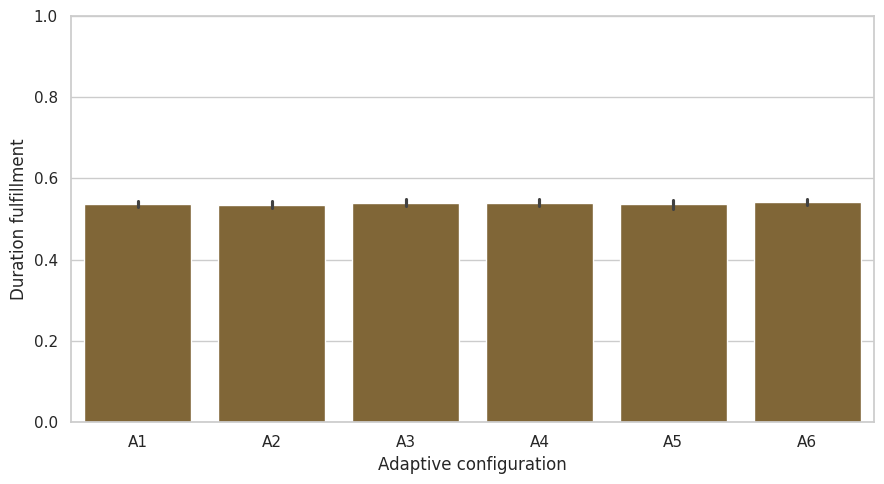

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


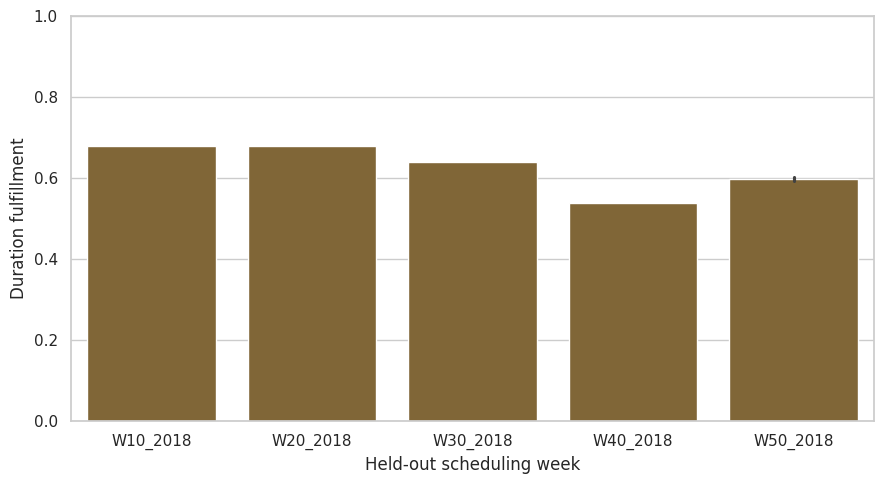

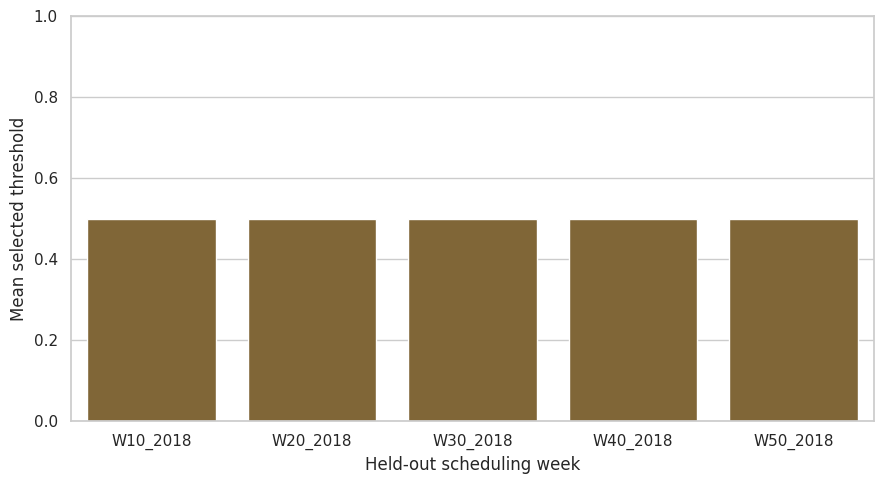

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
ADAPTIVE_COLOR = "#8C6A2B"

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(DIRS["figures"] / filename, dpi=300, bbox_inches="tight")
    plt.show()

# Validation performance by adaptive rule
plt.figure(figsize=(9, 5))
sns.barplot(
    data=stage_1_results,
    x="configuration_id",
    y="duration_fulfillment",
    errorbar="sd",
    color=ADAPTIVE_COLOR,
)
plt.xlabel("Adaptive configuration")
plt.ylabel("Duration fulfillment")
plt.ylim(0, 1)
save_figure("adaptive_validation_by_rule.png")

# Cross-week duration fulfillment
plt.figure(figsize=(9, 5))
sns.barplot(
    data=model_level_summary,
    x="test_week",
    y="duration_fulfillment",
    errorbar="sd",
    color=ADAPTIVE_COLOR,
)
plt.xlabel("Held-out scheduling week")
plt.ylabel("Duration fulfillment")
plt.ylim(0, 1)
save_figure("adaptive_cross_week_fulfillment.png")

# Mean threshold by week
plt.figure(figsize=(9, 5))
sns.barplot(
    data=model_level_summary,
    x="test_week",
    y="mean_selected_threshold",
    errorbar="sd",
    color=ADAPTIVE_COLOR,
)
plt.xlabel("Held-out scheduling week")
plt.ylabel("Mean selected threshold")
plt.ylim(0, 1)
save_figure("adaptive_mean_threshold_by_week.png")

## 11.2 Threshold Distribution, Episode Change and Stimulus-Activation Figures


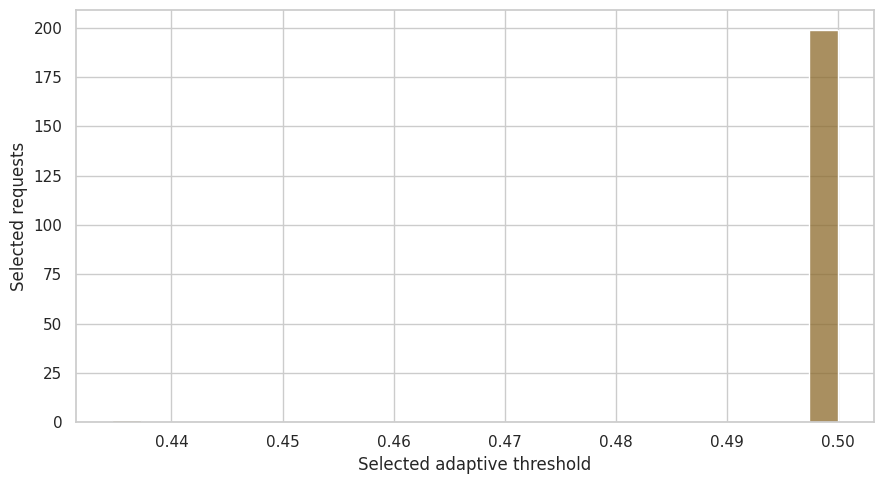

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


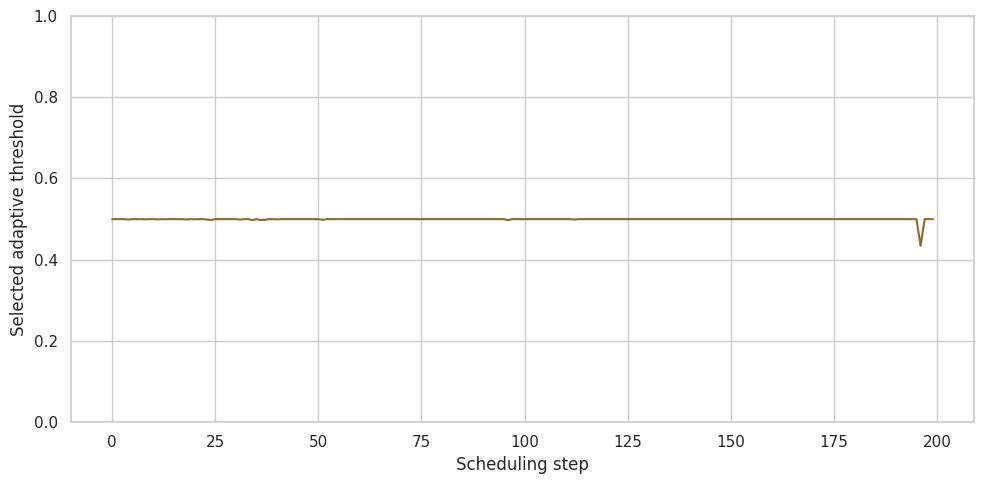

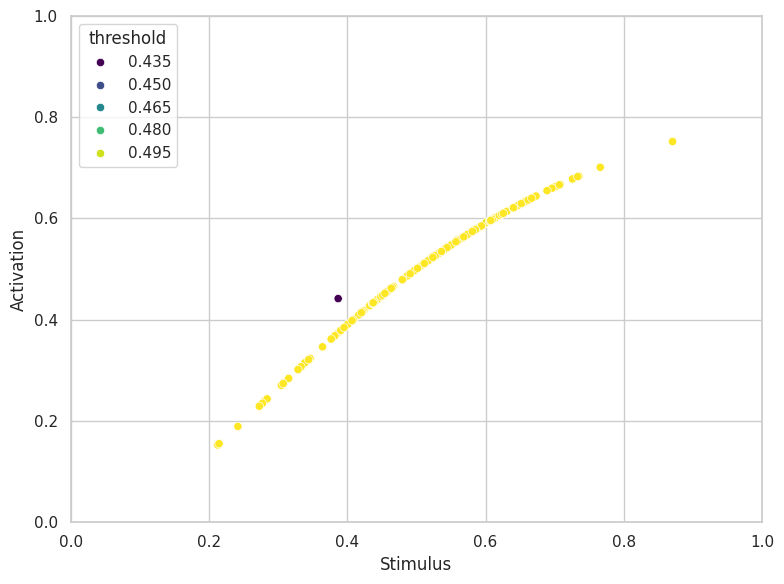

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
example_trace_path = Path(
    adaptive_cross_week_results.iloc[0]["threshold_path"]
)
example_trace = pd.read_parquet(example_trace_path)

plt.figure(figsize=(9, 5))
sns.histplot(
    data=example_trace,
    x="threshold",
    bins=25,
    color=ADAPTIVE_COLOR,
)
plt.xlabel("Selected adaptive threshold")
plt.ylabel("Selected requests")
save_figure("adaptive_threshold_distribution.png")

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=example_trace,
    x="step",
    y="threshold",
    color=ADAPTIVE_COLOR,
)
plt.xlabel("Scheduling step")
plt.ylabel("Selected adaptive threshold")
plt.ylim(0, 1)
save_figure("adaptive_threshold_during_episode.png")

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=example_trace,
    x="stimulus",
    y="activation",
    hue="threshold",
    palette="viridis",
)
plt.xlabel("Stimulus")
plt.ylabel("Activation")
plt.xlim(0, 1)
plt.ylim(0, 1)
save_figure("adaptive_stimulus_vs_activation.png")

## 11.3 Paired Model-Comparison Table

Run this cell after the plain-PPO and fixed-BEE owners provide their exported cross-week CSV files. Pairing uses fold, training seed and evaluation seed. Missing comparison files do not block completion of the adaptive stream.


In [ ]:
COMPARISON_FILES = {
    "plain_ppo": BEE_ROOT / "member_2_plain" / "results" / "plain_ppo_cross_week_results.csv",
    "fixed_bee": BEE_ROOT / "member_3_fixed" / "results" / "fixed_bee_cross_week_results.csv",
}

paired_comparison_rows = []
PAIR_KEYS = ["fold", "training_seed", "evaluation_seed"]
PAIR_METRICS = [
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "mission_fairness",
]

for comparison_method, comparison_path in COMPARISON_FILES.items():
    if not comparison_path.exists():
        print("Comparison file not available yet:", comparison_path)
        continue

    comparison_results = pd.read_csv(comparison_path)
    paired = adaptive_cross_week_results.merge(
        comparison_results,
        on=PAIR_KEYS,
        suffixes=("_adaptive", "_comparison"),
    )

    for metric in PAIR_METRICS:
        differences = (
            paired[f"{metric}_adaptive"]
            - paired[f"{metric}_comparison"]
        )
        paired_comparison_rows.append(
            {
                "comparison": f"adaptive_bee_minus_{comparison_method}",
                "metric": metric,
                "mean_difference": differences.mean(),
                "improved_cases": int((differences > 1e-12).sum()),
                "equal_cases": int(np.isclose(differences, 0.0).sum()),
                "worse_cases": int((differences < -1e-12).sum()),
            }
        )

paired_model_comparison = pd.DataFrame(paired_comparison_rows)
paired_model_comparison.to_csv(
    DIRS["results"] / "adaptive_paired_model_comparison.csv",
    index=False,
)

display(paired_model_comparison)

Comparison file not available yet: /content/drive/MyDrive/BEE/member_2_plain/results/plain_ppo_cross_week_results.csv
Comparison file not available yet: /content/drive/MyDrive/BEE/member_3_fixed/results/fixed_bee_cross_week_results.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


""


## 11.4 Report-Ready Figure Captions


In [ ]:
figure_captions = {
    "adaptive_validation_by_rule.png": "Mean duration fulfillment of the finalist adaptive-threshold configurations on validation week W40. Error bars show variation across training and request-order seeds.",
    "adaptive_cross_week_fulfillment.png": "Duration fulfillment of adaptive BEE across the five held-out scheduling weeks after freezing the adaptive rule.",
    "adaptive_mean_threshold_by_week.png": "Mean threshold associated with requests selected by adaptive BEE for each held-out scheduling week.",
    "adaptive_threshold_distribution.png": "Distribution of thresholds associated with requests selected during one representative held-out scheduling episode.",
    "adaptive_threshold_during_episode.png": "Change in the selected-request threshold across the construction of one representative schedule.",
    "adaptive_stimulus_vs_activation.png": "Relationship between stimulus and activation for selected requests, with color indicating the corresponding adaptive threshold.",
}

with open(DIRS["report"] / "adaptive_figure_captions.json", "w") as file:
    json.dump(figure_captions, file, indent=2)

for filename, caption in figure_captions.items():
    print(filename)
    print(caption)
    print()

adaptive_validation_by_rule.png
Mean duration fulfillment of the finalist adaptive-threshold configurations on validation week W40. Error bars show variation across training and request-order seeds.

adaptive_cross_week_fulfillment.png
Duration fulfillment of adaptive BEE across the five held-out scheduling weeks after freezing the adaptive rule.

adaptive_mean_threshold_by_week.png
Mean threshold associated with requests selected by adaptive BEE for each held-out scheduling week.

adaptive_threshold_distribution.png
Distribution of thresholds associated with requests selected during one representative held-out scheduling episode.

adaptive_threshold_during_episode.png
Change in the selected-request threshold across the construction of one representative schedule.

adaptive_stimulus_vs_activation.png
Relationship between stimulus and activation for selected requests, with color indicating the corresponding adaptive threshold.



# 12. Interpretation

## 12.1 Generate the Report-Ready Interpretation

This section identifies the best and worst folds, summarizes mean performance, reports threshold behavior and constraint validity and creates the method-specific limitations and recommended next-step discussion. The controlled hypothesis conclusion is completed after the paired plain-PPO and fixed-BEE results become available.


In [ ]:
best_fold = fold_level_summary.sort_values("duration_fulfillment", ascending=False).iloc[0]
worst_fold = fold_level_summary.sort_values("duration_fulfillment", ascending=True).iloc[0]
overall = overall_summary.iloc[0]

report_text = f"""# Adaptive-Threshold BEE

## Method Overview

The adaptive-threshold BEE model extends Maskable PPO with a response-threshold representation inspired by honeybee task activation. Each request is described using placement scarcity, resource contention and mission unmet demand. These components form a stimulus score, while the response threshold changes according to the current scheduling pressure. The resulting activation value is included in the observation provided to PPO. Physical feasibility remains controlled by the shared action mask and deterministic placement procedure, so the adaptive mechanism influences request selection without relaxing any scheduling constraint.

## Technical Implementation

The selected adaptive rule was {SELECTED_CONFIGURATION_ID}. Its frozen parameters were {json.dumps(SELECTED_CONFIGURATION)}. The model used the shared PPO configuration and reward, where each valid selection received its allocated-duration fraction plus 0.5 when minimum duration was satisfied. The requested training budget was {TOTAL_TIMESTEPS:,} timesteps and the controlled rollout-aligned budget was {CONTROLLED_TIMESTEPS:,} timesteps. All models used shared_v2 and every generated schedule was independently validated.

## Experiment Setup

Configurations A1 through A6 were screened using W10, W20 and W30 for training and W40 for validation. W50 was not inspected during model selection. After freezing the final rule, the model was retrained across five cross-week folds. Each trained model was evaluated using request-order seeds {EVALUATION_SEEDS}. The W50 fold additionally used training seeds 42, 123 and 456.

## Results

Across the five equally weighted held-out weeks, adaptive BEE achieved mean duration fulfillment of {overall['duration_fulfillment']:.4f}, minimum satisfaction of {overall['minimum_satisfaction_rate']:.4f}, full satisfaction of {overall['full_satisfaction_rate']:.4f} and mission fairness of {overall['mission_fairness']:.4f}. The best duration fulfillment occurred on {best_fold['test_week']} at {best_fold['duration_fulfillment']:.4f}, while the lowest occurred on {worst_fold['test_week']} at {worst_fold['duration_fulfillment']:.4f}. The mean selected threshold was {overall['mean_selected_threshold']:.4f} and mean selected activation was {overall['mean_selected_activation']:.4f}. All final schedules passed the independent validator with zero constraint violations.

## Interpretation

[Complete this paragraph after the paired plain-PPO and fixed-BEE results become available. State whether adaptive thresholds improved the controlled comparison, which metrics changed and whether lower thresholds caused over-activation.]

## Method-Specific Limitations

The adaptive rule is hand-designed and was selected from six predefined alternatives. Its pressure coefficients and selective indicator limits may not transfer unchanged to other scheduling datasets. The threshold is also an observation feature rather than a direct feasibility rule, so PPO may not always use it in the intended way. Further analysis should examine sensitivity to the threshold bounds and whether the adaptive state improves behavior under more varied scheduling instances.
"""

REPORT_PATH = DIRS["report"] / "adaptive_bee_report_section.md"
REPORT_PATH.write_text(report_text)

print("Saved:", REPORT_PATH)
print(report_text)

Saved: /content/drive/MyDrive/BEE/member_4_adaptive/report/adaptive_bee_report_section.md
# Adaptive-Threshold BEE

## Method Overview

The adaptive-threshold BEE model extends Maskable PPO with a response-threshold representation inspired by honeybee task activation. Each request is described using placement scarcity, resource contention and mission unmet demand. These components form a stimulus score, while the response threshold changes according to the current scheduling pressure. The resulting activation value is included in the observation provided to PPO. Physical feasibility remains controlled by the shared action mask and deterministic placement procedure, so the adaptive mechanism influences request selection without relaxing any scheduling constraint.

## Technical Implementation

The selected adaptive rule was A3. Its frozen parameters were {"scarcity_strength": 0.0, "contention_strength": 0.2, "unmet_strength": 0.0, "selective_mode": false, "stimulus_weights": [0.4, 0.4, 0

# 13. Save All Outputs

## 13.1 Final Deliverable and Completeness Check


In [ ]:
required_outputs = [
    DIRS["results"] / "adaptive_configuration_search.csv",
    DIRS["results"] / "adaptive_ablation_results.csv",
    DIRS["results"] / "adaptive_training_runs.csv",
    DIRS["results"] / "adaptive_cross_week_results.csv",
    DIRS["results"] / "adaptive_cross_week_summary.csv",
    DIRS["results"] / "adaptive_threshold_results.csv",
    DIRS["configs"] / "adaptive_bee_configuration.json",
    DIRS["report"] / "adaptive_bee_report_section.md",
]

missing_outputs = [
    str(path) for path in required_outputs if not path.exists()
]

assert not missing_outputs, f"Missing outputs: {missing_outputs}"
assert any(DIRS["models"].rglob("*.zip"))
assert any(DIRS["schedules"].glob("*.parquet"))
assert any(DIRS["thresholds"].glob("*.parquet"))
assert any(DIRS["figures"].glob("*.png"))

print("Adaptive BEE stream is complete.")
print("Final output folder:", MEMBER_ROOT)

Adaptive BEE stream is complete.
Final output folder: /content/drive/MyDrive/BEE/member_4_adaptive
